In [1]:
!pip install -q medmnist

import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import math, io, json, os, time, random
import matplotlib.pyplot as plt, pandas as pd
from PIL import Image
from scipy.ndimage import gaussian_filter
from sklearn.metrics import roc_auc_score
from medmnist import BloodMNIST
from torch.utils.data import DataLoader, TensorDataset
from google.colab import drive

drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/vae_shift'
os.makedirs(OUT, exist_ok=True)
torch.set_num_threads(os.cpu_count())

Mounted at /content/drive


In [2]:
tr = BloodMNIST(split='train', download=True, size=28)
te = BloodMNIST(split='test',  download=True, size=28)
Xtr_raw, Xte_raw = tr.imgs, te.imgs

CONDS = {
    'H1 warm':        dict(gain=(1.25, 1.00, 0.75), bright=1.0, blur=0.0),
    'H2 cool':        dict(gain=(0.80, 0.95, 1.25), bright=0.9, blur=0.0),
    'H3 dark':        dict(gain=(1.10, 0.85, 1.10), bright=0.7, blur=0.25),
    'H4 blurry':      dict(gain=(0.90, 1.15, 0.90), bright=1.1, blur=0.45),
    'Unseen':         dict(gain=(1.30, 0.90, 0.70), bright=0.8, blur=0.3),
}

def shift(X, gain, bright, blur):
    X = X.astype(np.float32) / 255.
    X = X * np.array(gain, dtype=np.float32) * bright
    if blur > 0:
        X = gaussian_filter(X, sigma=(0, blur, blur, 0))
    return np.clip(X, 0, 1)

def gray_world(X):
    m = X.mean(axis=(1, 2), keepdims=True)
    g = m.mean(axis=3, keepdims=True)
    return np.clip(X * g / (m + 1e-6), 0, 1)

def quant(X):  # back to 8-bit intensity levels, like a real saved image
    return (np.round(X * 255) / 255).astype(np.float32)

def prep(X01):
    return torch.from_numpy(X01).permute(0, 3, 1, 2).contiguous()

REF_TR = quant(Xtr_raw.astype(np.float32) / 255)
REF_TE = quant(Xte_raw.astype(np.float32) / 255)
SHIFTED = {c: quant(shift(Xte_raw, **cfg)) for c, cfg in CONDS.items()}
print(REF_TR.shape, REF_TE.shape, list(SHIFTED))

100%|██████████| 35.5M/35.5M [00:25<00:00, 1.41MB/s]


(11959, 28, 28, 3) (3421, 28, 28, 3) ['H1 warm', 'H2 cool', 'H3 dark', 'H4 blurry', 'Unseen']


In [3]:
D = 28 * 28 * 3
LOG2PI = math.log(2 * math.pi)

class VAE(nn.Module):
    def __init__(self, z=32):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Flatten(),
            nn.Linear(64 * 7 * 7, 256), nn.ReLU(), nn.Linear(256, 2 * z))
        self.dec = nn.Sequential(
            nn.Linear(z, 256), nn.ReLU(), nn.Linear(256, 64 * 7 * 7), nn.ReLU(),
            nn.Unflatten(1, (64, 7, 7)),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid())
        self.log_sigma = nn.Parameter(torch.full((1, 3, 1, 1), -2.0))  # learned per-channel noise

    def encode(self, x):
        mu, logvar = self.enc(x).chunk(2, 1)
        return mu, logvar.clamp(-8, 8)

    def log_px_z(self, x, xm):  # Gaussian log-likelihood, summed over pixels
        ls = self.log_sigma.clamp(min=-4.5)
        return (-0.5 * ((x - xm) / ls.exp()) ** 2 - ls - 0.5 * LOG2PI).flatten(1).sum(1)

def elbo(m, x):
    mu, logvar = m.encode(x)
    z = mu + (0.5 * logvar).exp() * torch.randn_like(mu)
    kl = 0.5 * (mu ** 2 + logvar.exp() - 1 - logvar).sum(1)
    return m.log_px_z(x, m.dec(z)) - kl

def train_vae(X01, seed=0, epochs=20):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = VAE(); opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    Xt = prep(X01); g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(Xt), batch_size=128, shuffle=True, generator=g)
    for ep in range(epochs):
        m.train(); tot = 0
        for (x,) in loader:
            loss = -elbo(m, x).mean()
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(x)
        if ep == 0 or (ep + 1) % 5 == 0:
            # continuous density, so bits/dim can be negative; lower is better
            print(f'epoch {ep+1}: -ELBO = {tot/len(Xt)/(D*math.log(2)):.3f} bits/dim')
    return m

In [4]:
@torch.no_grad()
def log_px(m, X01, k=16):
    """Importance-weighted estimate of log p(x) in nats (tighter than the ELBO)."""
    m.eval(); X = prep(X01); out = []
    for i in range(0, len(X), 256):
        x = X[i:i+256]
        mu, logvar = m.encode(x); std = (0.5 * logvar).exp()
        lw = []
        for _ in range(k):
            z = mu + std * torch.randn_like(std)
            lpz = (-0.5 * z ** 2 - 0.5 * LOG2PI).sum(1)
            lqz = (-0.5 * ((z - mu) / std) ** 2 - torch.log(std) - 0.5 * LOG2PI).sum(1)
            lw.append(m.log_px_z(x, m.dec(z)) + lpz - lqz)
        out.append(torch.logsumexp(torch.stack(lw), 0) - math.log(k))
    return torch.cat(out).numpy()

def png_bits(X01):
    out = []
    for x in X01:
        b = io.BytesIO()
        Image.fromarray((x * 255).round().astype(np.uint8)).save(b, format='PNG', optimize=True)
        out.append(len(b.getvalue()) * 8)
    return np.array(out, dtype=np.float64)

def scores(m, X01):
    nll_bits = -log_px(m, X01) / math.log(2)
    return nll_bits, nll_bits - png_bits(X01)   # raw NLL, complexity-corrected score

def evaluate(m, ref, shifted, label):
    r_nll, r_cc = scores(m, ref); rows = []
    for c, X in shifted.items():
        s_nll, s_cc = scores(m, X)
        y = np.r_[np.zeros(len(ref)), np.ones(len(X))]
        rows.append(dict(setting=label, condition=c,
                         auroc_nll=roc_auc_score(y, np.r_[r_nll, s_nll]),
                         auroc_corrected=roc_auc_score(y, np.r_[r_cc, s_cc]),
                         frac_nll_up=float((s_nll > r_nll).mean()),   # same images, before vs after shift
                         d_bpd=float((s_nll - r_nll).mean() / D),
                         d_png_bpd=float((png_bits(X) - png_bits(ref)).mean() / D)))
    return rows, (r_nll, r_cc)

In [5]:
t = time.time(); _ = train_vae(REF_TR, epochs=1); print(f'1 epoch: {time.time()-t:.0f}s')

epoch 1: -ELBO = -0.431 bits/dim
1 epoch: 36s


In [6]:
t = time.time()
vae_raw = train_vae(REF_TR)
rows_raw, ref_raw = evaluate(vae_raw, REF_TE, SHIFTED, 'raw')

vae_gw = train_vae(quant(gray_world(REF_TR)))
SHIFTED_GW = {c: quant(gray_world(X)) for c, X in SHIFTED.items()}
rows_gw, _ = evaluate(vae_gw, quant(gray_world(REF_TE)), SHIFTED_GW, 'gray-world')

res = pd.DataFrame(rows_raw + rows_gw)
res.to_csv(f'{OUT}/results.csv', index=False)
print(res.round(3).to_string(index=False)); print(f'total {time.time()-t:.0f}s')

epoch 1: -ELBO = -0.431 bits/dim
epoch 5: -ELBO = -1.227 bits/dim
epoch 10: -ELBO = -1.503 bits/dim
epoch 15: -ELBO = -1.670 bits/dim
epoch 20: -ELBO = -1.773 bits/dim
epoch 1: -ELBO = -0.465 bits/dim
epoch 5: -ELBO = -1.237 bits/dim
epoch 10: -ELBO = -1.513 bits/dim
epoch 15: -ELBO = -1.667 bits/dim
epoch 20: -ELBO = -1.763 bits/dim
   setting condition  auroc_nll  auroc_corrected  frac_nll_up  d_bpd  d_png_bpd
       raw   H1 warm      0.998            1.000        0.998  1.772     -0.474
       raw   H2 cool      0.966            0.974        0.999  0.617     -0.143
       raw   H3 dark      0.855            0.984        0.958  0.325     -0.487
       raw H4 blurry      0.930            0.983        1.000  0.510     -0.343
       raw    Unseen      1.000            1.000        1.000  3.732     -0.486
gray-world   H1 warm      0.503            0.868        0.469 -0.007     -0.426
gray-world   H2 cool      0.459            0.635        0.307 -0.038     -0.150
gray-world   H3 dark    

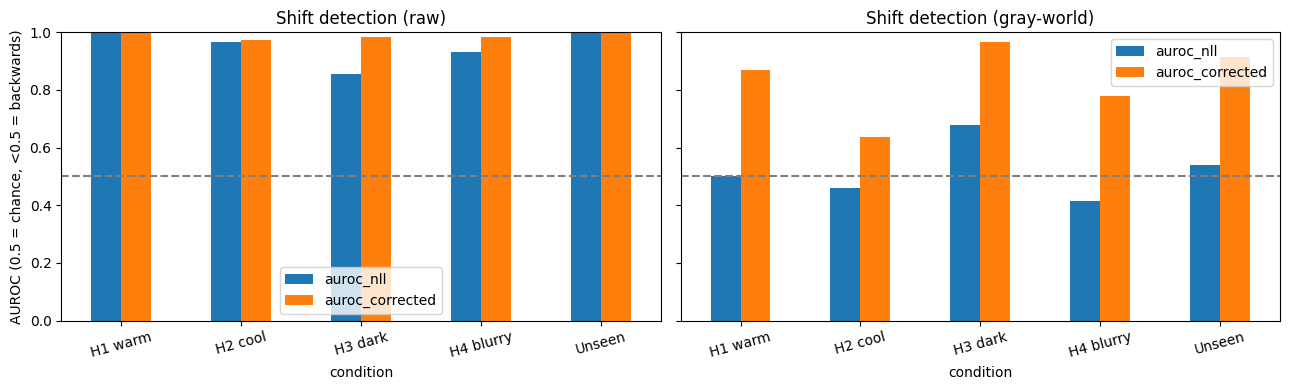

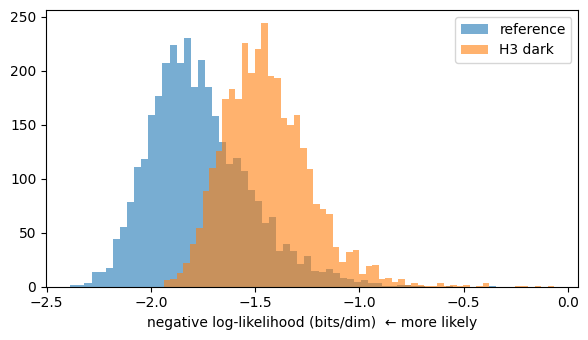

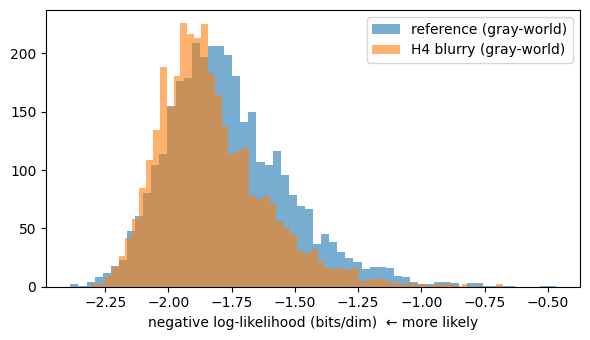

In [7]:
# 1) Detection AUROC: raw likelihood vs complexity-corrected, with and without gray-world
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for j, s in enumerate(['raw', 'gray-world']):
    sub = res[res.setting == s].set_index('condition')[['auroc_nll', 'auroc_corrected']]
    sub.plot.bar(ax=ax[j], rot=15); ax[j].axhline(0.5, ls='--', c='gray')
    ax[j].set_title(f'Shift detection ({s})'); ax[j].set_ylim(0, 1)
ax[0].set_ylabel('AUROC (0.5 = chance, <0.5 = backwards)')
plt.tight_layout(); plt.savefig(f'{OUT}/detection_auroc.png', dpi=200); plt.show()

# 2) Raw setting, dark hospital: likelihood still detects it
s_nll, _ = scores(vae_raw, SHIFTED['H3 dark'])
plt.figure(figsize=(6, 3.5))
plt.hist(ref_raw[0] / D, bins=60, alpha=0.6, label='reference')
plt.hist(s_nll / D, bins=60, alpha=0.6, label='H3 dark')
plt.xlabel('negative log-likelihood (bits/dim)  ← more likely'); plt.legend(); plt.tight_layout()
plt.savefig(f'{OUT}/h3_hist.png', dpi=200); plt.show()

# 3) Gray-world setting, blurry hospital: blurred images look MORE likely (the failure case)
r_gw, _ = scores(vae_gw, quant(gray_world(REF_TE)))
s_gw, _ = scores(vae_gw, SHIFTED_GW['H4 blurry'])
plt.figure(figsize=(6, 3.5))
plt.hist(r_gw / D, bins=60, alpha=0.6, label='reference (gray-world)')
plt.hist(s_gw / D, bins=60, alpha=0.6, label='H4 blurry (gray-world)')
plt.xlabel('negative log-likelihood (bits/dim)  ← more likely'); plt.legend(); plt.tight_layout()
plt.savefig(f'{OUT}/h4_gw_hist.png', dpi=200); plt.show()